
Dimensiones originales después del preprocesamiento: (1000, 8)
Dimensiones después de PCA: (1000, 2)
Varianza explicada por componente: [0.45105709 0.17756495]
Varianza acumulada: 0.6286220379358065


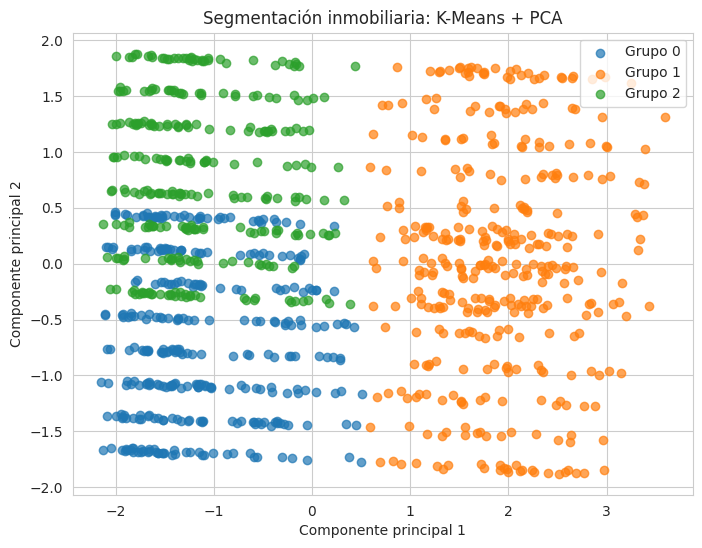


Perfil de los grupos (Promedios):
              Precio arriendo  Área m²  Habitaciones  Baños  Antig[uedad
Grupo_KMeans                                                            
0                  2063615.30    62.21          1.87    1.0         8.60
1                  6353185.81   156.07          4.03    1.5         8.31
2                  1974711.38    60.85          1.84    2.0         8.49

Distribución por localidad:
Localidad     Chapinero  Suba  Usaquén
Grupo_KMeans                          
0                  0.34  0.35     0.32
1                  0.31  0.31     0.38
2                  0.36  0.35     0.29


In [16]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 1. Cargar el dataset
df = pd.read_csv("DATASET_INmuebles.csv", sep=";", encoding="utf-8")

# Conservar el identificador
ids = df["Inmueble"]

variables_numericas = [
    "Precio arriendo",
    "Área m²",
    "Habitaciones",
    "Baños",
    "Antig[uedad"
]

variables_categoricas = ["Localidad"]

# 1.5 LIMPIEZA DE DATOS (¡La nueva magia!)
for col in variables_numericas:
    if df[col].dtype == 'object':
        # Convertimos a string temporalmente, quitamos los puntos (miles)
        # y convertimos a número. "errors='coerce'" convierte lo que no pueda a NaN.
        df[col] = df[col].astype(str).str.replace('.', '', regex=False)
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Opcional: Si hay valores vacíos (NaN) después de la limpieza, los rellenamos con 0
# (o podrías borrar esas filas con df.dropna(subset=variables_numericas))
df[variables_numericas] = df[variables_numericas].fillna(0)

X = df[variables_numericas + variables_categoricas]

# 2. Preprocesamiento
preprocesamiento = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), variables_numericas),
        ("categoricas",
         OneHotEncoder(handle_unknown="ignore"),
         variables_categoricas)
    ]
)

X_preparado = preprocesamiento.fit_transform(X)

# 3. Experimento A: K-Means sobre los datos preprocesados
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

grupos = kmeans.fit_predict(X_preparado)

df["Grupo_KMeans"] = grupos

# 4. PCA para representar los datos en dos dimensiones
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_preparado)

print("\nDimensiones originales después del preprocesamiento:",
      X_preparado.shape)

print("Dimensiones después de PCA:", X_pca.shape)

print("Varianza explicada por componente:",
      pca.explained_variance_ratio_)

print("Varianza acumulada:",
      pca.explained_variance_ratio_.sum())

# 5. Gráfica de los grupos
plt.figure(figsize=(8, 6))
for grupo in sorted(df["Grupo_KMeans"].unique()):
    seleccion = grupos == grupo

    plt.scatter(
        X_pca[seleccion, 0],
        X_pca[seleccion, 1],
        label=f"Grupo {grupo}",
        alpha=0.7
    )

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Segmentación inmobiliaria: K-Means + PCA")
plt.legend()
plt.grid(True)
plt.show()

# 6. Perfil comercial de los grupos
print("\nPerfil de los grupos (Promedios):")
print(
    df.groupby("Grupo_KMeans")[
        variables_numericas
    ].mean().round(2)
)

# Distribución por localidad dentro de cada grupo
print("\nDistribución por localidad:")
print(pd.crosstab(
    df["Grupo_KMeans"],
    df["Localidad"],
    normalize="index"
).round(2))

In [17]:
# ============================================================
# K-Means modificado: Segmentación de inmuebles en arriendo
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import unicodedata
import re
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# ---------- 1. Lectura del dataset ----------
df = pd.read_csv("DATASET_INmuebles.csv", sep=";", encoding="utf-8-sig")

# ---------- 2. Limpieza robusta de nombres de columnas ----------
def limpiar_nombre(col):
    col = unicodedata.normalize("NFKD", col).encode("ascii", "ignore").decode("utf-8")
    col = col.strip().replace(" ", "_")
    col = re.sub(r"[^\w]", "", col)
    return col

df.columns = [limpiar_nombre(c) for c in df.columns]
print("Columnas limpias:", df.columns.tolist())

# Eliminar columna Estrato duplicada (si existe)
if "Estrato.1" in df.columns:
    df = df.drop(columns=["Estrato.1"])

# ---------- 3. Conversión de precio (formato 1.413.951 -> 1413951) ----------
df["Precio_arriendo"] = (
    df["Precio_arriendo"].astype(str)
      .str.replace(".", "", regex=False)
      .astype(float)
)

# Identificador (se conserva, NO se usa para distancias)
id_inmueble = df["Inmueble"]

# ---------- 4. Selección de variables numéricas para clustering ----------
X = df[["Area_m2", "Habitaciones", "Banos", "Antiguedad", "Estrato", "Precio_arriendo"]]

# ---------- 5. Escalamiento ----------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---------- 6. K-Means con distintos parámetros ----------
def ejecutar_kmeans(n_clusters):
    modelo = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    modelo.fit(X_scaled)
    df[f"cluster_k{n_clusters}"] = modelo.labels_
    resumen = df.groupby(f"cluster_k{n_clusters}")[X.columns].mean().round(1)
    return modelo, resumen

modelo2, resumen2 = ejecutar_kmeans(2)
modelo3, resumen3 = ejecutar_kmeans(3)
modelo4, resumen4 = ejecutar_kmeans(4)

print("\n=== Resumen k=2 ===\n", resumen2)
print("\n=== Resumen k=3 ===\n", resumen3)
print("\n=== Resumen k=4 ===\n", resumen4)

Columnas limpias: ['Inmueble', 'Area_m2', 'Habitaciones', 'Estrato', 'Precio_arriendo', 'Banos', 'Antiguedad', 'Localidad', 'Tipo_Inmueble', 'Estrato1']

=== Resumen k=2 ===
             Area_m2  Habitaciones  Banos  Antiguedad  Estrato  Precio_arriendo
cluster_k2                                                                    
0              61.0           1.8    1.5         8.5      3.0        1984490.1
1             154.6           4.0    1.5         8.4      5.5        6300711.6

=== Resumen k=3 ===
             Area_m2  Habitaciones  Banos  Antiguedad  Estrato  Precio_arriendo
cluster_k3                                                                    
0              61.3           1.8    1.0         8.6      3.0        2000101.3
1             154.6           4.0    1.5         8.4      5.5        6300711.6
2              60.7           1.8    2.0         8.5      3.0        1967061.1

=== Resumen k=4 ===
             Area_m2  Habitaciones  Banos  Antiguedad  Estrato  Precio_